In [1]:
!pip -q install -U ultralytics open_clip_torch opencv-python av

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 72.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 MB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.9 MB/s eta 0:00:00


In [2]:
import sys, platform

In [3]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import transforms, models
from torchvision.ops import nms, box_iou
from torchvision.io import read_video

In [4]:
from torch.utils.data import DataLoader, Dataset, Subset
from PIL import Image
import matplotlib.pyplot as plt

In [5]:
try:
  import cv2
  HAS_CV2 = True
except Excpetion as e:
  HAS_CV2 = False
  print("cv2 import failed:",e)

In [6]:
import open_clip

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA available", torch.cuda.is_available())

torch: 2.9.0+cu126
torchvision: 0.24.0+cu126
CUDA available True


In [7]:
def set_seed(seed: int = 42):
  import random, numpy as np, torch
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic = True
  torch.backends.cudnn.benchmark = False

In [8]:
set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [9]:
boxes = torch.tensor([
    [10,10,50,50],
    [12,12,52,52],
    [60,60,100,100],
    [55,60,95,105],
    [15,10,48,45],
], dtype = torch.float32)

scores = torch.tensor([0.9,0.8,0.7,0.6,0.65],dtype= torch.float32)

iou_mat = box_iou(boxes, boxes)
print(iou_mat)

tensor([[1.0000, 0.8223, 0.0000, 0.0000, 0.7219],
        [0.8223, 1.0000, 0.0000, 0.0000, 0.6537],
        [0.0000, 0.0000, 1.0000, 0.7000, 0.0000],
        [0.0000, 0.0000, 0.7000, 1.0000, 0.0000],
        [0.7219, 0.6537, 0.0000, 0.0000, 1.0000]])


In [10]:
keep = nms(boxes, scores, 0.5)
print(keep.tolist())
print(boxes[keep].tolist())

[0, 2]
[[10.0, 10.0, 50.0, 50.0], [60.0, 60.0, 100.0, 100.0]]


In [11]:
from pathlib import Path
from torchvision.datasets.utils import download_and_extract_archive

DATA_ROOT = Path('./data_pennfudan')
DATA_ROOT.mkdir(parents = True, exist_ok = True)

url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
zip_name = "PennFudanPed.zip"

if not (DATA_ROOT/ "PennFudanPed").exists():
  download_and_extract_archive(url,download_root = str(DATA_ROOT),filename=zip_name)
  print("Downloaded & Extracted PennFudanPed")
else:
  print("PennFudanped already Exists")

print("data root:",(DATA_ROOT / "PennFudanPed").resolve())

100%|██████████| 53.7M/53.7M [00:01<00:00, 34.5MB/s]


Downloaded & Extracted PennFudanPed
data root: /content/data_pennfudan/PennFudanPed


In [12]:
class PennFudanDataset(Dataset):
    def __init__(self, root: str, transforms=None):
        self.root = Path(root)
        self.transforms = transforms

        self.imgs = sorted((self.root /"PNGImages").glob("*.png"))
        self.masks = sorted((self.root /"PedMasks").glob("*.png"))

        assert len(self.imgs) == len(self.masks), "images and masks length mismatch"

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self,idx):
        img_path = self.imgs[idx]
        mask_path = self.masks[idx]

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)
        mask = np.array(mask)

        obj_ids = np.unique(mask)
        obj_ids = obj_ids[obj_ids != 0]

        boxes = []

        for obj_id in obj_ids:
            pos = np.where(mask == obj_id)
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.as_tensor(boxes, dtype = torch.float32)

        labels = torch.ones((len(obj_ids),),dtype=torch.int64)

        image_id = torch.tensor([idx])

        area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])

        iscrowd = torch.zeros((len(obj_ids),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd
        }

        if self.transforms is not None:
            img = self.transforms(img)

        return img, target

    def collate_fn(batch):
        return tuple(zip(*batch))

In [13]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

ds = PennFudanDataset(str(DATA_ROOT / "PennFudanPed"), transforms = transform)
print("Dataset Length:",len(ds))

img, tgt = ds[0]
print("img:", img.shape, img.dtype)
print("tgt keys:", tgt.keys())
print("boxes:", tgt["boxes"].shape, tgt["boxes"][:2])
print("labels:", tgt["labels"].shape, tgt["labels"][:5])

Dataset Length: 170
img: torch.Size([3, 536, 559]) torch.float32
tgt keys: dict_keys(['boxes', 'labels', 'image_id', 'area', 'iscrowd'])
boxes: torch.Size([2, 4]) tensor([[159., 181., 301., 430.],
        [419., 170., 534., 485.]])
labels: torch.Size([2]) tensor([1, 1])


In [14]:
def draw_boxes_on_tensor_image(img_tensor, boxes, color = (0,255,0), thickness =2):
  img = (img_tensor.permute(1,2,0).numpy() * 255).astype(np.uint8)
  img = img.copy()
  for b in boxes:
    x1, y1, x2, y2 = [int(v) for v in b ]
    cv2.rectangle(img, (x1,y1),(x2,y2),color, thickness)
  return img

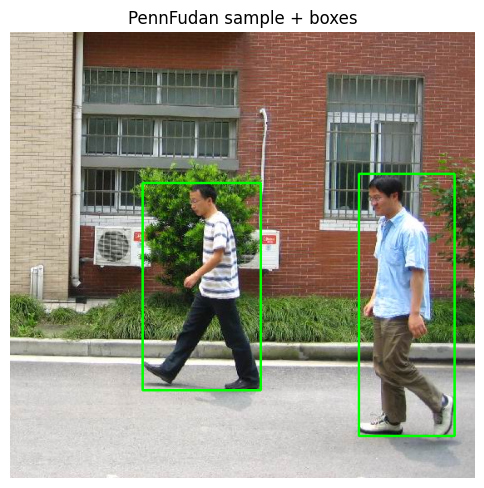

In [15]:
img, tgt = ds[0]
vis = draw_boxes_on_tensor_image(img,tgt['boxes'])
plt.figure(figsize=(6,6))
plt.imshow(vis)
plt.axis('off')
plt.title('PennFudan sample + boxes')
plt.show()

In [16]:
indices = torch.randperm(len(ds)).tolist()
split = int(0.8 * len(ds))
train_idx, test_idx = indices[:split], indices[split:]

train_ds = Subset(ds, train_idx)
test_ds = Subset(ds, test_idx)

train_loader = DataLoader(train_ds, batch_size = 2, shuffle = True, num_workers = 2, collate_fn = PennFudanDataset.collate_fn)
test_loader = DataLoader(test_ds, batch_size =1, shuffle = False, num_workers =2, collate_fn = PennFudanDataset.collate_fn)

print("train:", len(train_ds))
print("test:", len(test_ds))

train: 136
test: 34


In [17]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn

In [18]:
model_det = fasterrcnn_resnet50_fpn(weights="DEFAULT").to(device)
model_det.eval()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 187MB/s]


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [19]:
img, target = ds[0]
x = img.to(device)

with torch.no_grad():
  pred = model_det([x])[0]

print(pred.keys())
print(pred['boxes'].shape,pred['boxes'][:2])
print(pred['labels'][:10])
print(pred['scores'][:10])

dict_keys(['boxes', 'labels', 'scores'])
torch.Size([5, 4]) tensor([[419.6865, 170.0683, 536.0842, 493.7452],
        [159.0727, 180.3606, 298.8194, 434.4603]], device='cuda:0')
tensor([ 1,  1, 32, 32, 32], device='cuda:0')
tensor([0.9997, 0.9996, 0.5827, 0.2102, 0.0943], device='cuda:0')


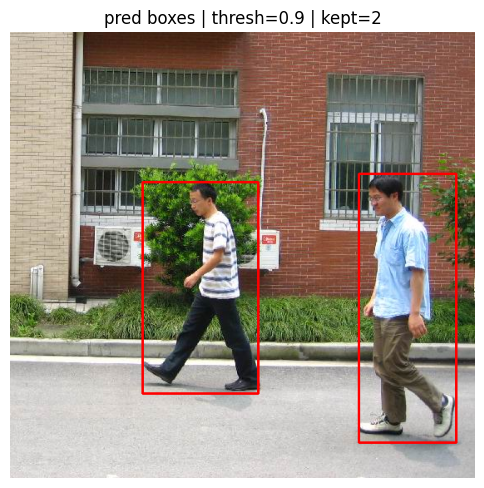

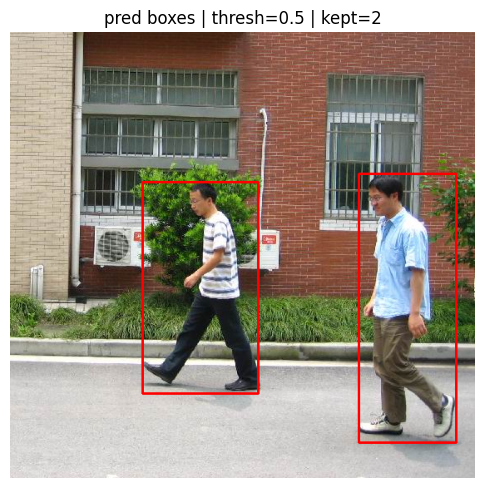

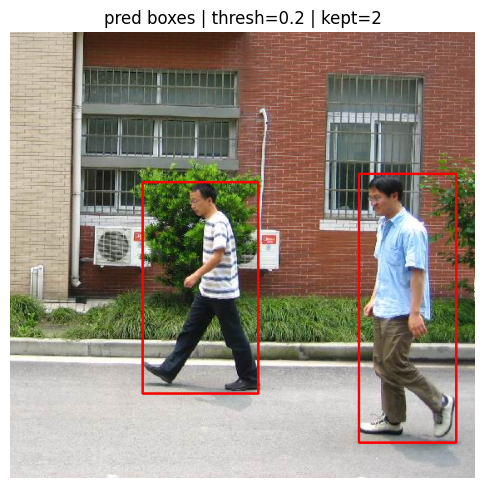

In [20]:
COCO_PERSON_ID = 1

def visualize_predictions(img_tensor, pred, score_thresh=0.5, only_person=False):
    boxes = pred["boxes"].cpu()
    labels = pred["labels"].cpu()
    scores = pred["scores"].cpu()
    keep = scores >= score_thresh
    boxes = boxes[keep]
    labels = labels[keep]
    scores = scores[keep]
    if only_person:
        keep2 = labels == COCO_PERSON_ID
        boxes = boxes[keep2]
        labels = labels[keep2]
        scores = scores[keep2]
    vis = draw_boxes_on_tensor_image(img_tensor, boxes, color=(255,0,0), thickness=2)
    plt.figure(figsize=(6,6))
    plt.imshow(vis)
    plt.axis("off")
    plt.title(f"pred boxes | thresh={score_thresh} | kept={len(boxes)}")
    plt.show()
img, _ = ds[0]

with torch.no_grad():
  pred = model_det([img.to(device)])[0]

visualize_predictions(img, pred, score_thresh=0.9, only_person=True)
visualize_predictions(img, pred, score_thresh=0.5, only_person=True)
visualize_predictions(img, pred, score_thresh=0.2, only_person=True)

해석 포인트(강의에서 반드시 짚기)
- threshold를 내리면 박스가 늘어난다.
- 늘어난 박스는 fp일수도, fn일수도 있다.

=> threshold는 precision vs recall trade-off와 직결
- 서비스 목적(안전/보안/검색/추천)에 따라 다른 threshold를 선택.

In [21]:
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection import fasterrcnn_resnet50_fpn

In [22]:
def get_fasterrcnn_for_num_classes(num_classes: int):
  model = fasterrcnn_resnet50_fpn(weights="DEFAULT")
  in_features = model.roi_heads.box_predictor.cls_score.in_features
  model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
  return model

In [23]:
num_classes = 2
model_ft = get_fasterrcnn_for_num_classes(num_classes).to(device)
print('model ready')

model ready


In [24]:
def train_one_epoch_detection(model, optimizer, loader, device, print_freq = 20):
  model.train()
  running = 0.0
  n = 0

  for i, (images, targets) in enumerate(loader):
    images = [img.to(device) for img in images]
    targets = [{k: v.to(device) for k,v in t.items()} for t in targets]

    loss_dict = model(images, targets)
    losses = sum(loss for loss in loss_dict.values())

    optimizer.zero_grad(set_to_none = True)
    losses.backward()
    optimizer.step()

    running += losses.item()
    n += 1

    if (i+1) % print_freq == 0:
      ld = {k: float(v.item()) for k,v in loss_dict.items()}
      print(f"[iter {i+1}] loss={losses.item():.4f} | " + " | ".join([f"{k}={ld[k]:.3f}" for k in ld]))

  return running / max(n,1)

In [25]:
@torch.no_grad()
def inference_detection(model, images, device):
  model.eval()
  images = [img.to(device) for img in images]
  preds = model(images)
  return preds

In [26]:
params = [p for p in model_ft.parameters() if p.requires_grad]
optimizer = optim.SGD(params, lr = 0.005, momentum = 0.9, weight_decay = 0.0005)

In [28]:
num_epochs = 2
loss_hist = []

for epoch in range(num_epochs):
  loss = train_one_epoch_detection(model_ft, optimizer, train_loader, device, print_freq = 50)
  loss_hist.append(loss)
  print(f"[epoch {epoch+1}/{num_epochs}] avg_loss={loss:.4f}")

[iter 50] loss=0.1358 | loss_classifier=0.056 | loss_box_reg=0.071 | loss_objectness=0.002 | loss_rpn_box_reg=0.007
[epoch 1/2] avg_loss=0.1120
[iter 50] loss=0.0607 | loss_classifier=0.015 | loss_box_reg=0.041 | loss_objectness=0.000 | loss_rpn_box_reg=0.004
[epoch 2/2] avg_loss=0.0986


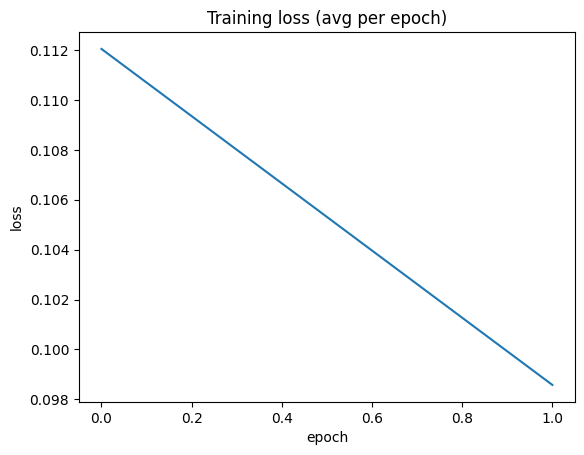

In [29]:
plt.figure()
plt.plot(loss_hist)
plt.title("Training loss (avg per epoch)")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.show()

In [37]:
@torch.no_grad()
def quick_iou_check(model, loader, device, score_thresh=0.5, max_images=10):
    model.eval()
    ious = []
    cnt = 0
    for images, targets in loader:
        images = [img.to(device) for img in images]
        preds = model(images)
        for img, pred, tgt in zip(images, preds, targets):
            gt_boxes = tgt["boxes"]  # CPU
            # filter by score
            scores = pred["scores"].cpu()
            boxes = pred["boxes"].cpu()
            keep = scores >= score_thresh
            boxes = boxes[keep]
            scores = scores[keep]
            if len(boxes) == 0:
                ious.append(0.0)
            else:
                # choose top-1 prediction
                top = torch.argmax(scores)
                pb = boxes[top:top+1]
                # IoU with all gt, take max
                iou = box_iou(pb, gt_boxes).max().item()
                ious.append(iou)
            cnt += 1
            if cnt >= max_images:
                return float(np.mean(ious)), ious
    return float(np.mean(ious)), ious

In [38]:
mean_iou, iou_list = quick_iou_check(model_ft, test_loader, device, score_thresh=0.5, max_images=20)
print("Quick mean IoU:", mean_iou)
print("IoU list:", [round(x,3) for x in iou_list[:10]], "...")

Quick mean IoU: 0.9070210546255112
IoU list: [0.94, 0.943, 0.905, 0.846, 0.949, 0.9, 0.906, 0.909, 0.817, 0.89] ...


Before top scores: [0.9994509816169739, 0.9952281713485718, 0.7256065607070923, 0.5646917819976807, 0.46251416206359863]
After top scores: [0.9964568018913269, 0.9655306935310364]


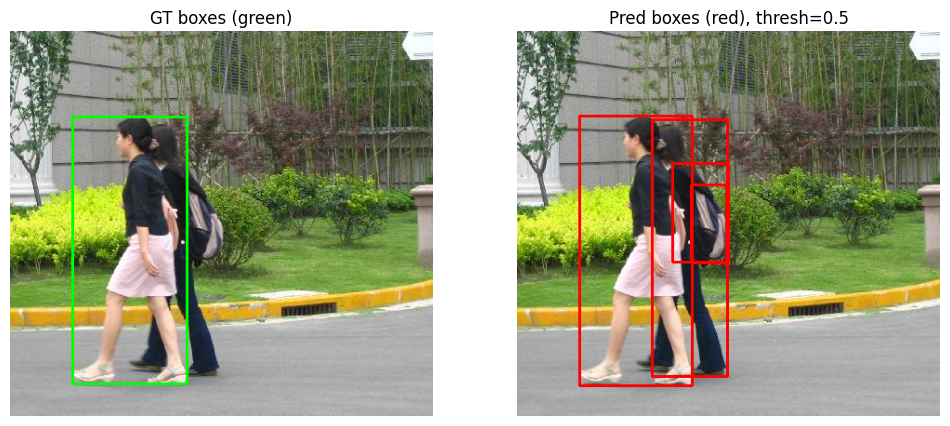

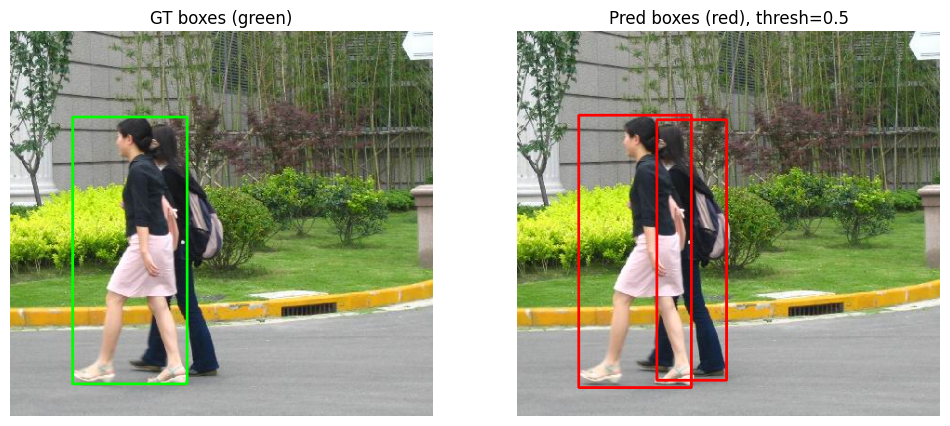

In [39]:
def get_pred_single(model, img_tensor, device):
    model.eval()
    with torch.no_grad():
        pred = model([img_tensor.to(device)])[0]
    return pred
def visualize_pred_vs_gt(img_tensor, gt_boxes, pred, score_thresh=0.5):
    # GT
    gt_vis = draw_boxes_on_tensor_image(img_tensor, gt_boxes, color=(0,255,0), thickness=2)
    # Pred filtered
    boxes = pred["boxes"].cpu()
    scores = pred["scores"].cpu()
    keep = scores >= score_thresh
    boxes = boxes[keep]
    pred_vis = draw_boxes_on_tensor_image(img_tensor, boxes, color=(255,0,0), thickness=2)
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.imshow(gt_vis); plt.axis("off"); plt.title("GT boxes (green)")
    plt.subplot(1,2,2)
    plt.imshow(pred_vis); plt.axis("off"); plt.title(f"Pred boxes (red), thresh={score_thresh}")
    plt.show()
# 테스트 샘플 하나
img, tgt = ds[1]
pred_before = get_pred_single(model_det, img, device)     # COCO pretrained
pred_after  = get_pred_single(model_ft, img, device)      # fine-tuned
print("Before top scores:", pred_before["scores"][:5].cpu().tolist())
print("After top scores:", pred_after["scores"][:5].cpu().tolist())
visualize_pred_vs_gt(img, tgt["boxes"], pred_before, score_thresh=0.5)
visualize_pred_vs_gt(img, tgt["boxes"], pred_after, score_thresh=0.5)

#YOLO

In [34]:
from ultralytics import YOLO
# 모델 크기: n/s/m/l/x (n이 가장 가벼움)
# 강의/데모는 속도 우선이면 yolov8n.pt, 품질 우선이면 yolov8s~m 권장
yolo8 = YOLO("yolov8n.pt")  # 최초 실행 시 가중치 다운로드(인터넷 필요)
print("YOLOv8 loaded")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8 loaded


num boxes: 2


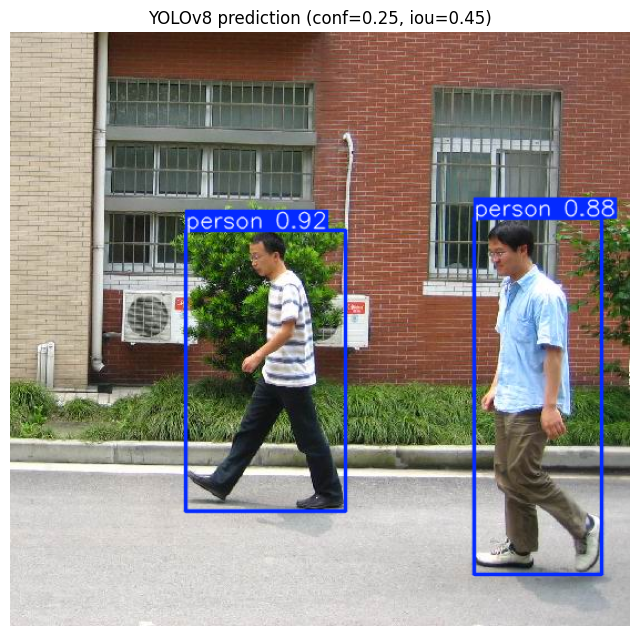

In [35]:
sample_img_path = ds.imgs[0]
pil_img = Image.open(sample_img_path).convert("RGB")
results = yolo8.predict(
    source=pil_img,
    conf=0.25,
    iou=0.45,
    imgsz=640,
    verbose=False
)
r0 = results[0]
print("num boxes:", len(r0.boxes))
vis_bgr = r0.plot()
vis_rgb = cv2.cvtColor(vis_bgr, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8,8))
plt.imshow(vis_rgb)
plt.axis("off")
plt.title("YOLOv8 prediction (conf=0.25, iou=0.45)")
plt.show()

In [36]:
# YOLOv8 결과 파싱: boxes.xyxy / conf / cls
boxes_xyxy = r0.boxes.xyxy.cpu().numpy()      # [N,4]
scores = r0.boxes.conf.cpu().numpy()          # [N]
clses  = r0.boxes.cls.cpu().numpy().astype(int)  # [N]
import pandas as pd
df_yolo = pd.DataFrame({
    "xmin": boxes_xyxy[:,0],
    "ymin": boxes_xyxy[:,1],
    "xmax": boxes_xyxy[:,2],
    "ymax": boxes_xyxy[:,3],
    "conf": scores,
    "cls": clses,
    "name": [r0.names[c] for c in clses],
})
df_yolo.sort_values("conf", ascending=False).head(10)

,xmin,ymin,xmax,ymax,conf,cls,name
0,158.628586,179.954300,302.273773,432.212616,0.920085,0,person
1,418.798004,168.943771,533.872437,489.389130,0.879511,0,person


from matplotlib import pyplot as plt
_df_0['index'].plot(kind='hist', bins=20, title='index')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['xmin'].plot(kind='hist', bins=20, title='xmin')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['ymin'].plot(kind='hist', bins=20, title='ymin')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['xmax'].plot(kind='hist', bins=20, title='xmax')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_4.plot(kind='scatter', x='index', y='xmin', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

... (7 outputs left out)

from matplotlib import pyplot as plt
_df_12['index'].plot(kind='line', figsize=(8, 4), title='index')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_13['xmin'].plot(kind='line', figsize=(8, 4), title='xmin')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_14['ymin'].plot(kind='line', figsize=(8, 4), title='ymin')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_15['xmax'].plot(kind='line', figsize=(8, 4), title='xmax')
plt.gca().spines[['top', 'right']].set_visible(False)

In [44]:
def run_yolo_with_params(conf=0.25, iou = 0.45, imgsz = 640, max_det = 100):
  res = yolo8.predict(pil_img, conf=conf, iou = iou, imgsz=imgsz, max_det=max_det, verbose=False)[0]
  vis = cv2.cvtColor(res.plot(),cv2.COLOR_BGR2RGB)
  plt.figure(figsize=(7,7))
  plt.imshow(vis)
  plt.axis('off')
  plt.title(f"YOLOv8 conf={conf} iou={iou} imgsz={imgsz} | N={len(res.boxes)}")
  plt.show()
  return res

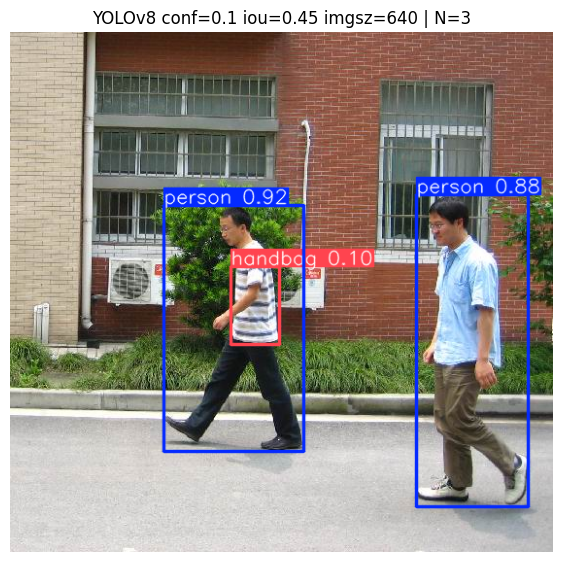

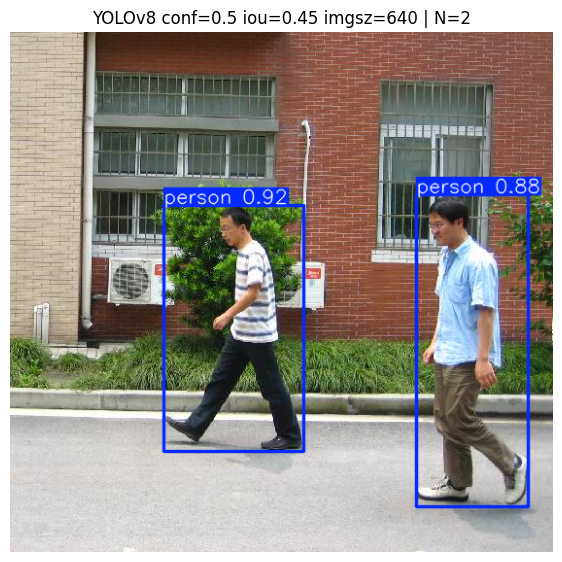

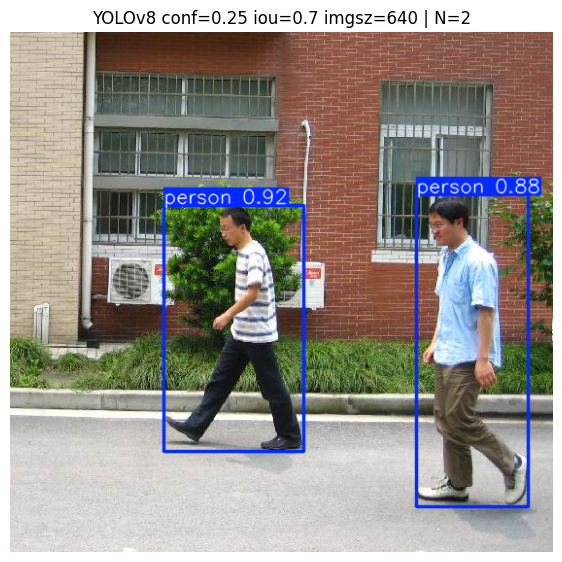

In [45]:
_ = run_yolo_with_params(conf=0.10,iou=0.45)
_ = run_yolo_with_params(conf=0.50,iou=0.45)
_ = run_yolo_with_params(conf=0.25,iou=0.70)

In [46]:
def box_cxcywh_to_xyxy(x):
  cx, cy, w, h = x.unbind(-1)
  x1 = cx - 0.5 * w
  y1 = cy - 0.5 * h
  x2 = cx + 0.5 * w
  y2 = cy + 0.5 * h
  return torch.stack([x1,y1,x2,y2], dim = -1)

In [47]:
def rescale_bboxes(out_bbox, size):
  img_w, img_h = size
  b = out_bbox
  b = b * torch.tensor([img_w, img_h, img_w, img_h], dtype = torch.float32)
  return b

#DETR

In [1]:
import sys, subprocess
import torch
from PIL import Image

In [2]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [3]:
print(device)

cuda


In [4]:
DETR_BACKEND = None
detr = None
detr_transform = None
processor = None

In [5]:
def _pip_install(pkgs):
    """Jupyter/Colab에서도 안전하게 동작하는 pip 설치 헬퍼"""
    cmd = [sys.executable, "-m", "pip", "install", "-U", *pkgs]
    print("Running:", " ".join(cmd))
    subprocess.check_call(cmd)
def _try_load_torchvision_detr():
    global detr, detr_transform, DETR_BACKEND
    try:
        from torchvision.models.detection import detr_resnet50, DETR_ResNet50_Weights
        weights = DETR_ResNet50_Weights.DEFAULT
        detr = detr_resnet50(weights=weights).to(device).eval()
        detr_transform = weights.transforms()
        DETR_BACKEND = "torchvision"
        print("DETR loaded from torchvision:", weights)
        return True
    except Exception as e:
        print("torchvision DETR unavailable in this env:", repr(e))
        return False
def _load_hf_detr():
    global detr, processor, DETR_BACKEND
    try:
        from transformers import DetrImageProcessor, DetrForObjectDetection
    except Exception:
        _pip_install(["transformers", "timm", "accelerate"])
        from transformers import DetrImageProcessor, DetrForObjectDetection
    processor = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50")
    detr = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50").to(device).eval()
    DETR_BACKEND = "hf"
    print("DETR loaded from HuggingFace: facebook/detr-resnet-50")

In [6]:
if not _try_load_torchvision_detr():
    _load_hf_detr()
@torch.no_grad()
def detr_predict(pil_img: Image.Image, score_thresh: float = 0.5):
    """
    DETR 공통 예측 함수 (torchvision/HF 모두 지원)
    Returns:
      boxes_xyxy: (N,4) pixel coords
      scores: (N,)
      labels: (N,)
    """
    assert detr is not None, "DETR model not loaded."
    if DETR_BACKEND == "torchvision":
        # torchvision DETR: pred_logits/pred_boxes (normalized cxcywh) 형태가 일반적
        x = detr_transform(pil_img).unsqueeze(0).to(device)  # (1,3,H,W)
        out = detr(x)
        # 일부 버전에서는 이미 postprocess된 형태가 올 수도 있어 방어적으로 처리
        if isinstance(out, (list, tuple)) and len(out) > 0 and isinstance(out[0], dict) and "boxes" in out[0]:
            boxes = out[0]["boxes"].detach().cpu()
            scores = out[0]["scores"].detach().cpu()
            labels = out[0]["labels"].detach().cpu()
            keep = scores >= score_thresh
            return boxes[keep], scores[keep], labels[keep]
        if isinstance(out, dict) and "pred_logits" in out and "pred_boxes" in out:
            pred_logits = out["pred_logits"][0] if out["pred_logits"].dim() == 3 else out["pred_logits"]
            pred_boxes  = out["pred_boxes"][0]  if out["pred_boxes"].dim() == 3  else out["pred_boxes"]
        else:
            raise RuntimeError("Unexpected torchvision DETR output format.")
        probs = pred_logits.softmax(-1)
        scores, labels = probs[..., :-1].max(-1)  # 마지막은 no-object
        keep = scores >= score_thresh
        scores = scores[keep].detach().cpu()
        labels = labels[keep].detach().cpu()
        boxes_cxcywh = pred_boxes[keep].detach().cpu()  # normalized
        # cxcywh (0~1) -> xyxy (pixels)
        w, h = pil_img.size
        cx, cy, bw, bh = boxes_cxcywh.unbind(-1)
        x1 = (cx - 0.5 * bw) * w
        y1 = (cy - 0.5 * bh) * h
        x2 = (cx + 0.5 * bw) * w
        y2 = (cy + 0.5 * bh) * h
        boxes_xyxy = torch.stack([x1, y1, x2, y2], dim=-1)
        return boxes_xyxy, scores, labels
    elif DETR_BACKEND == "hf":
        # HF DETR: processor가 전/후처리를 담당 (박스는 pixel xyxy로 바로 복원 가능)
        inputs = processor(images=pil_img, return_tensors="pt").to(device)
        outputs = detr(**inputs)
        target_sizes = torch.tensor([pil_img.size[::-1]], device=device)  # (h, w)
        results = processor.post_process_object_detection(
            outputs, target_sizes=target_sizes, threshold=score_thresh
        )[0]
        boxes = results["boxes"].detach().cpu()
        scores = results["scores"].detach().cpu()
        labels = results["labels"].detach().cpu()
        return boxes, scores, labels
    else:
        raise RuntimeError(f"Unknown DETR_BACKEND={DETR_BACKEND}")

torchvision DETR unavailable in this env: ImportError("cannot import name 'detr_resnet50' from 'torchvision.models.detection' (/usr/local/lib/python3.12/dist-packages/torchvision/models/detection/__init__.py)")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for conv1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.weight: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pass `assign=True` to assign items in the state dictionary to their corresponding key in the module instead of copying them in place?)
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:2446: UserWarning: for bn1.bias: copying from a non-meta parameter in the checkpoint to a meta parameter in the current model, which is a no-op. (Did you mean to pas

DETR loaded from HuggingFace: facebook/detr-resnet-50


In [7]:
def box_cxcywh_to_xyxy(x):
  cx, cy, w, h = x.unbind(-1)
  x1 = cx - 0.5 * w
  y1 = cy - 0.5 * h
  x2 = cx + 0.5 * w
  y2 = cy + 0.5 * h
  return torch.stack([x1.y1.x2.y2], dim = -1)

In [8]:
def rescale_bboxes(out_bbox, size):
  img_w, img_h = size
  b = out_bbox
  b = b * torch.tensor([img_w, img_h, img_w, img_h], dtype = torch.float32)
  return b

In [9]:
import time
from PIL import Image
import torch

def time_inference(fn, n_warmup=3, n_iters=10):
    # warmup
    for _ in range(n_warmup):
        _ = fn()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n_iters):
        _ = fn()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t1 = time.time()
    return (t1 - t0) / n_iters

In [15]:
# timing에 사용할 이미지 준비 (ds가 있으면 ds[0], 없으면 pil_img를 그대로 사용)
if "pil_img" in globals() and isinstance(pil_img, Image.Image):
    _pil = pil_img
elif "ds" in globals() and len(ds) > 0: # Added len(ds) check for robustness
    sample0 = ds[0]
    img0 = sample0[0] if isinstance(sample0, (list, tuple)) else sample0
    if isinstance(img0, Image.Image):
        _pil = img0
    else:
        # tensor -> PIL
        try:
            from torchvision import transforms
            _pil = transforms.ToPILImage()(img0)
        except Exception:
            raise RuntimeError("Cannot build PIL image for timing. Please define `pil_img` as a PIL.Image.")
else:
    raise RuntimeError("No image found for timing. Please run the image loading cell to define `pil_img` first, or ensure the dataset is populated.")
# YOLOv8 timing
if "yolo8" in globals() and yolo8 is not None:
    def yolo8_fn():
        _ = yolo8.predict(_pil, conf=0.25, iou=0.45, imgsz=640, verbose=False)
        return _
    t_yolo = time_inference(yolo8_fn)
    print("YOLOv8 avg sec/iter:", t_yolo)
else:
    print("YOLOv8 model(yolo8) not found; skip YOLOv8 timing.")
# DETR timing (핵심: detr(x) 금지 → detr_predict(pil_img) 사용)
if "detr" in globals() and detr is not None:
    def detr_fn():
        _ = detr_predict(_pil, score_thresh=0.25)
        return _
    t_detr = time_inference(detr_fn)
    print(f"DETR({DETR_BACKEND}) avg sec/iter:", t_detr)
else:
    print("DETR not available; skip DETR timing.")

YOLOv8 model(yolo8) not found; skip YOLOv8 timing.
DETR(hf) avg sec/iter: 0.09418332576751709


### 데이터셋 정의 및 로딩 재구성

이전 오류들을 해결하고 데이터셋이 올바르게 로드되도록, 필요한 모든 임포트와 데이터셋 클래스 정의, 그리고 데이터 다운로드 및 `pil_img` 로딩 과정을 다시 구성하겠습니다.

In [12]:
import torch
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.datasets.utils import download_and_extract_archive

# DATA_ROOT 정의 (이전 셀에서 정의되었지만, 확실히 하기 위해 다시 포함)
DATA_ROOT = Path('./data_pennfudan')
DATA_ROOT.mkdir(parents=True, exist_ok=True)

# PennFudanDataset 클래스 정의 (이전 셀에서 정의되었지만, 확실히 하기 위해 다시 포함)
class PennFudanDataset(Dataset):
    def __init__(self, root: str, transforms=None):
        self.root = Path(root)
        self.transforms = transforms

        self.imgs = sorted(list((self.root /"PNGImages").glob("*.png")))
        self.masks = sorted(list((self.root /"PedMasks").glob("*.png")))

        assert len(self.imgs) == len(self.masks), "images and masks length mismatch"

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self,idx):
        img_path = self.imgs[idx]
        mask_path = self.masks[idx]

        img = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)
        mask = np.array(mask)

        obj_ids = np.unique(mask)
        obj_ids = obj_ids[obj_ids != 0]

        boxes = []

        for obj_id in obj_ids:
            pos = np.where(mask == obj_id)
            ymin = np.min(pos[0])
            ymax = np.max(pos[0])
            xmin = np.min(pos[1])
            xmax = np.max(pos[1])
            boxes.append([xmin, ymin, xmax, ymax])

        boxes = torch.as_tensor(boxes, dtype = torch.float32)

        labels = torch.ones((len(obj_ids),),dtype=torch.int64)

        image_id = torch.tensor([idx])

        area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])

        iscrowd = torch.zeros((len(obj_ids),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": image_id,
            "area": area,
            "iscrowd": iscrowd
        }

        if self.transforms is not None:
            img = self.transforms(img)

        return img, target

    def collate_fn(batch):
        return tuple(zip(*batch))

In [13]:
url = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
zip_name = "PennFudanPed.zip"

if not (DATA_ROOT / "PennFudanPed").exists():
  download_and_extract_archive(url, download_root=str(DATA_ROOT), filename=zip_name)
  print("Downloaded & Extracted PennFudanPed")
else:
  print("PennFudanped already Exists")

print("data root:", (DATA_ROOT / "PennFudanPed").resolve())

100%|██████████| 53.7M/53.7M [00:01<00:00, 33.7MB/s]


Downloaded & Extracted PennFudanPed
data root: /content/data_pennfudan/PennFudanPed


In [14]:
transform = transforms.Compose([
    transforms.ToTensor(),
])

ds = PennFudanDataset(str(DATA_ROOT / "PennFudanPed"), transforms = transform)
print("Dataset Length:", len(ds))

# pil_img 변수 정의
if len(ds) > 0:
    sample_img_path = ds.imgs[0]
    pil_img = Image.open(sample_img_path).convert("RGB")
    print("pil_img is now loaded.")
else:
    print("Warning: Dataset is empty, pil_img could not be loaded.")
    pil_img = None # Ensure pil_img is defined as None if dataset is empty

Dataset Length: 170
pil_img is now loaded.


In [19]:
!pip -q install open_clip_torch
import open_clip

model_name = "ViT-B-32"
pretrained = "laion2b_s34b_b79k"
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(
    model_name, pretrained=pretrained
)
clip_model = clip_model.to(device).eval()

tokenizer = open_clip.get_tokenizer(model_name)
HAS_OPENCLIP = True # Define HAS_OPENCLIP here
print("CLIP loaded:", model_name, pretrained)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.1 MB/s eta 0:00:00


open_clip_model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

CLIP loaded: ViT-B-32 laion2b_s34b_b79k


In [20]:
@torch.no_grad()
def clip_encode_text(texts):
    tokens = tokenizer(texts).to(device)
    feat = clip_model.encode_text(tokens)
    feat = feat / feat.norm(dim=-1, keepdim=True)
    return feat
@torch.no_grad()
def clip_encode_images(pil_images):
    xs = torch.stack([clip_preprocess(im) for im in pil_images], dim=0).to(device)
    feat = clip_model.encode_image(xs)
    feat = feat / feat.norm(dim=-1, keepdim=True)
    return feat

In [21]:
candidate_texts = [
    "a photo of a person",
    "a photo of a pedestrian",
    "a photo of a bicycle",
    "a photo of a car",
    "a photo of a dog",
    "a close-up portrait of a person",
]
text_feat = clip_encode_text(candidate_texts)
img_feat = clip_encode_images([pil_img])
sim = (img_feat @ text_feat.T).squeeze(0)
topk = torch.topk(sim, k=min(5, len(candidate_texts)))
print("Top prompts for the whole image:")
for score, idx in zip(topk.values.tolist(), topk.indices.tolist()):
    print(f"  {candidate_texts[idx]:35s} | sim={score:.4f}")

Top prompts for the whole image:
  a photo of a pedestrian             | sim=0.2686
  a photo of a person                 | sim=0.2146
  a photo of a bicycle                | sim=0.1756
  a photo of a car                    | sim=0.1621
  a photo of a dog                    | sim=0.1336


In [22]:
def crop_with_pad(img_rgb_uint8, box_xyxy, pad_ratio=0.1):
    H, W = img_rgb_uint8.shape[:2]
    x1, y1, x2, y2 = box_xyxy
    bw = max(1.0, (x2 - x1))
    bh = max(1.0, (y2 - y1))
    px = bw * pad_ratio
    py = bh * pad_ratio
    x1p = int(max(0, x1 - px))
    y1p = int(max(0, y1 - py))
    x2p = int(min(W - 1, x2 + px))
    y2p = int(min(H - 1, y2 + py))
    if x2p <= x1p or y2p <= y1p:
        return None
    return img_rgb_uint8[y1p:y2p, x1p:x2p]

@torch.no_grad()
def clip_topk_for_crops(crops_rgb_uint8, candidate_texts, topk=3):
    pil_crops = [Image.fromarray(c) for c in crops_rgb_uint8]
    img_feat = clip_encode_images(pil_crops)
    text_feat = clip_encode_text(candidate_texts)
    sim = img_feat @ text_feat.T
    topv, topi = torch.topk(sim, k=min(topk, len(candidate_texts)), dim=1)
    return topv.cpu().numpy(), topi.cpu().numpy()

In [23]:
img_rgb = np.array(pil_img)

In [24]:
tag_candidates = [
    "a person",
    "a pedestrian",
    "a worker wearing a helmet",
    "a person walking",
    "a person standing",
    "a person riding a bicycle",
    "a backpack",
    "a bag",
]

In [29]:
results = yolo8.predict(
    source=pil_img,
    conf=0.25,
    iou=0.45,
    imgsz=640,
    verbose=False
)
r0 = results[0]
boxes = r0.boxes.xyxy.cpu().numpy()
confs = r0.boxes.conf.cpu().numpy()
crops=[]
kept=[]
for b, s in zip(boxes, confs):
    x1,y1,x2,y2 = b
    if (x2-x1) < 10 or (y2-y1) < 10:
        continue
    crop = crop_with_pad(img_rgb, b, pad_ratio=0.15)
    if crop is None:
        continue
    crops.append(crop)
    kept.append((b,s))
print("kept crops:", len(crops))

kept crops: 2


In [28]:
!pip -q install ultralytics
from ultralytics import YOLO
# 모델 크기: n/s/m/l/x (n이 가장 가벼움)
# 강의/데모는 속도 우선이면 yolov8n.pt, 품질 우선이면 yolov8s~m 권장
yolo8 = YOLO("yolov8n.pt")  # 최초 실행 시 가중치 다운로드(인터넷 필요)
print("YOLOv8 loaded")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.7 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8 loaded


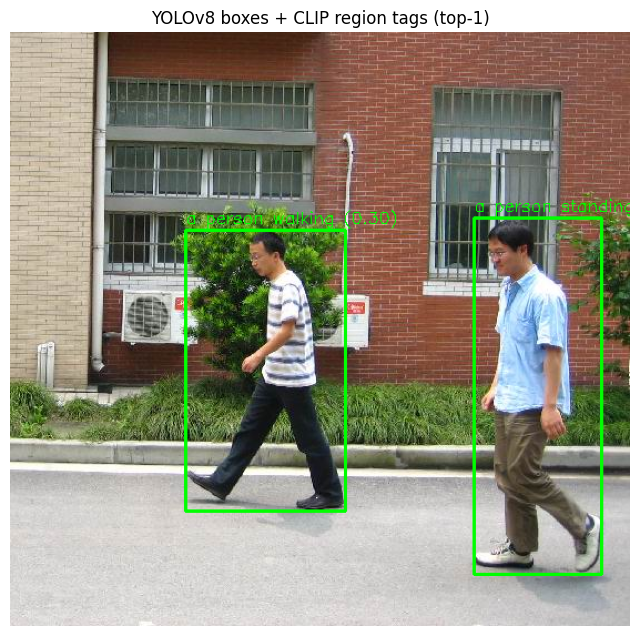

In [30]:
if len(crops) > 0:
    topv, topi = clip_topk_for_crops(crops, tag_candidates, topk=3)
    vis = img_rgb.copy()
    for (b,s), idxs, vals in zip(kept, topi, topv):
        x1,y1,x2,y2 = [int(v) for v in b]
        label = tag_candidates[int(idxs[0])]
        score = float(vals[0])
        cv2.rectangle(vis, (x1,y1), (x2,y2), (0,255,0), 2)
        cv2.putText(vis, f"{label} ({score:.2f})", (x1, max(0,y1-6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1)
    plt.figure(figsize=(8,8))
    plt.imshow(vis)
    plt.axis("off")
    plt.title("YOLOv8 boxes + CLIP region tags (top-1)")
    plt.show()

In [1]:
import torch
import numpy as np
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from torchvision.datasets.utils import download_and_extract_archive

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
if "pil_img" not in globals() or not isinstance(pil_img, Image.Image):
    raise RuntimeError("`pil_img` (PIL.Image)가 없습니다. 이미지 로딩/선택 셀을 먼저 실행하세요.")
if "detr" not in globals() or detr is None:
    print("DETR not available; skip.")
else:
    img_rgb = np.array(pil_img)  # RGB
    # 필요한 유틸이 없으면 간단 대체 버전 제공
    if "crop_with_pad" not in globals():
        def crop_with_pad(img_rgb, box_xyxy, pad_ratio=0.15):
            h, w = img_rgb.shape[:2]
            x1, y1, x2, y2 = [float(v) for v in box_xyxy]
            bw, bh = (x2 - x1), (y2 - y1)
            if bw <= 1 or bh <= 1:
                return None
            padw, padh = bw * pad_ratio, bh * pad_ratio
            xx1 = max(0, int(x1 - padw))
            yy1 = max(0, int(y1 - padh))
            xx2 = min(w, int(x2 + padw))
            yy2 = min(h, int(y2 + padh))
            if xx2 <= xx1 or yy2 <= yy1:
                return None
            return img_rgb[yy1:yy2, xx1:xx2].copy()
    if "clip_topk_for_crops" not in globals():
        raise RuntimeError("`clip_topk_for_crops`가 없습니다. CLIP 로딩/임베딩 셀을 먼저 실행하세요.")
    if "tag_candidates" not in globals():
        tag_candidates = [
            "a person", "a pedestrian", "a worker wearing a helmet",
            "a car", "a bus", "a bicycle", "a backpack", "a bag"
        ]
    boxes, scores, labels = detr_predict(pil_img, score_thresh=0.7)
    if len(boxes) == 0:
        print("No DETR detections above threshold.")
    else:
        boxes_np = boxes.numpy()
        crops = []
        kept = []
        for b in boxes_np:
            x1, y1, x2, y2 = b
            if (x2 - x1) < 10 or (y2 - y1) < 10:
                continue
            crop = crop_with_pad(img_rgb, b, pad_ratio=0.15)
            if crop is None:
                continue
            crops.append(crop)
            kept.append(b)
        if len(crops) == 0:
            print("All crops filtered out (too small / invalid).")
        else:
            topv, topi = clip_topk_for_crops(crops, tag_candidates, topk=1)
            vis = img_rgb.copy()
            for b, idxs, vals in zip(kept, topi, topv):
                x1, y1, x2, y2 = [int(v) for v in b]
                label = tag_candidates[int(idxs[0])]
                score = float(vals[0])
                cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 2)
                cv2.putText(
                    vis, f"{label} ({score:.2f})",
                    (x1, max(0, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1
                )
            plt.figure(figsize=(8, 8))
            plt.imshow(vis)
            plt.axis("off")
            plt.title(f"DETR({DETR_BACKEND}) boxes + CLIP region tags (top-1)")
            plt.show()

RuntimeError: `pil_img` (PIL.Image)가 없습니다. 이미지 로딩/선택 셀을 먼저 실행하세요.

In [3]:
import os
from pathlib import Path
VIDEO_DIR = Path("./video_samples")
VIDEO_DIR.mkdir(parents=True, exist_ok=True)
video_path = VIDEO_DIR / "sample.mp4"

In [4]:
url_candidates = [
    "https://raw.githubusercontent.com/pytorch/vision/main/test/assets/videos/v_SoccerJuggling_g01_c01.avi",
    "https://raw.githubusercontent.com/pytorch/vision/main/test/assets/videos/v_Skiing_g01_c01.avi",
    "https://storage.googleapis.com/gtv-videos-bucket/sample/ForBiggerJoyrides.mp4",
]

In [5]:
def try_download(urls, out_path):
    import urllib.request
    for u in urls:
        try:
            print("Trying download:", u)
            urllib.request.urlretrieve(u, out_path)
            print("Downloaded to:", out_path)
            return True
        except Exception as e:
            print("Failed:", e)
    return False
if not video_path.exists():
    ok = try_download(url_candidates, str(video_path))
    if not ok:
        print("\nDownload failed. Please upload your own video (mp4/avi) to:", video_path)
else:
    print("Video already exists:", video_path)
print("Current video_path:", video_path.resolve())

Trying download: https://raw.githubusercontent.com/pytorch/vision/main/test/assets/videos/v_SoccerJuggling_g01_c01.avi
Failed: HTTP Error 404: Not Found
Trying download: https://raw.githubusercontent.com/pytorch/vision/main/test/assets/videos/v_Skiing_g01_c01.avi
Failed: HTTP Error 404: Not Found
Trying download: https://storage.googleapis.com/gtv-videos-bucket/sample/ForBiggerJoyrides.mp4
Downloaded to: video_samples/sample.mp4
Current video_path: /content/video_samples/sample.mp4


In [6]:
!pip -q install av
import av # Explicitly import av after installation
from torchvision.io import read_video
assert Path(video_path).exists(), "video file not found. Please download or upload first."
video, audio, info = read_video(str(video_path), pts_unit="sec")
print("video shape:", video.shape)   # [T,H,W,C]
print("video dtype:", video.dtype)

print("audio shape:", audio.shape)
print("info:", info)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 MB 17.5 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/torchvision/io/_video_deprecation_warning.py:9: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(


ImportError: PyAV is not installed, and is necessary for the video operations in torchvision.
See https://github.com/mikeboers/PyAV#installation for instructions on how to
install PyAV on your system.


In [9]:
import math

In [ ]:
def show_frames_grid(video_thwc, frame_indices, title = "frames"):
  n = len(frame_indices)
  cols = min(n, 6)
  rows = math.ceil(n / cols)
  plt.figure(figsize=(3*cols, 3*rows))
  for i, idx in enumerate(frame_indices):
      idx = int(idx)
      idx = max(0, min(idx, video_thwc.shape[0]-1))
      frame = video_thwc[idx].cpu().numpy()
      plt.subplot(rows, cols, i+1)
      plt.imshow(frame)
      plt.axis("off")
      plt.title(f"t={idx}")
plt.suptitle(title)
plt.show()

In [ ]:
T = video.shape[0]
frame_indices = np.linspace(0, T-1, 10, dtype=np.int32)
show_frames_grid(video, frame_indices, title="Uniformly sampled frames")

In [11]:
def sample_clip_uniform(video_thwc, clip_len=16, sampling_rate=2, start=None):
    '''
    video_thwc: Tensor[T,H,W,C]
    clip_len: number of frames returned
    sampling_rate: step between frames
    start: None이면 center, 정수면 해당 프레임부터
    return: clip Tensor[clip_len,H,W,C]
    '''
    T = video_thwc.shape[0]
    span = (clip_len - 1) * sampling_rate + 1  # 필요한 원본 프레임 범위 길이
    if start is None:
        # center start
        start = max(0, (T - span) // 2)
    else:
        start = int(start)
        start = max(0, min(start, max(0, T-1)))
    idx = [start + i * sampling_rate for i in range(clip_len)]
    # padding: idx가 T를 넘으면 마지막 프레임 사용
    idx = [min(i, T-1) for i in idx]
    clip = video_thwc[idx]
    return clip, idx


In [ ]:
clip1, idx1 = sample_clip_uniform(video, clip_len=16, sampling_rate=1, start=None)
clip2, idx2 = sample_clip_uniform(video, clip_len=16, sampling_rate=4, start=None)
print("clip1 idx:", idx1[:8], "...")
print("clip2 idx:", idx2[:8], "...")
show_frames_grid(video, idx1[:12], title="indices used (sampling_rate=1)")
show_frames_grid(video, idx2[:12], title="indices used (sampling_rate=4)")

In [ ]:
# clip: [T,H,W,C] uint8
clip = clip1  # [16,H,W,C]
print("clip:", clip.shape, clip.dtype)
# (T,H,W,C) -> (T,C,H,W)
clip_tchw = clip.permute(0, 3, 1, 2).float() / 255.0
print("clip_tchw:", clip_tchw.shape, clip_tchw.dtype)
# (T,C,H,W) -> (C,T,H,W)
clip_cthw = clip_tchw.permute(1, 0, 2, 3)
print("clip_cthw:", clip_cthw.shape)
# batch 추가: (1,C,T,H,W)
x = clip_cthw.unsqueeze(0).to(device)
print("x:", x.shape, x.dtype, x.device)

In [13]:
import torch.nn as nn

In [14]:
class Tiny3DCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(3, 16, kernel_size=(3,3,3), stride=(1,2,2), padding=(1,1,1)), # T 유지, H/W down
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=(1,2,2)),  # 시간축은 유지, 공간만 down
            nn.Conv3d(16, 32, kernel_size=3, stride=(2,2,2), padding=1),  # 시간/공간 모두 down
            nn.ReLU(),
            nn.AdaptiveAvgPool3d((1,1,1)),  # (T,H,W) -> (1,1,1)
        )
        self.fc = nn.Linear(32, num_classes)
    def forward(self, x):
        # x: (N,C,T,H,W)
        x = self.net(x)
        x = x.flatten(1)  # (N,32)
        x = self.fc(x)    # (N,num_classes)
        return x

In [ ]:
tiny = Tiny3DCNN(num_classes=5).to(device)
print(tiny)
with torch.no_grad():
    out = tiny(x)
print("tiny output:", out.shape)

In [ ]:
labels_path = Path("./kinetics_400_labels.txt")
if not labels_path.exists():
    import urllib.request
    try:
        url = "https://raw.githubusercontent.com/deepmind/kinetics-i3d/master/data/label_map.txt"
        urllib.request.urlretrieve(url, labels_path)
        print("Downloaded labels to", labels_path)
    except Exception as e:
        print("Label download failed:", e)
        print("Proceed without labels file.")
labels = None
if labels_path.exists():
    # label_map.txt format may vary; we try to parse robustly
    raw = labels_path.read_text(encoding="utf-8", errors="ignore").splitlines()
    # Extract text after colon if exists, else whole line
    parsed = []
    for line in raw:
        line = line.strip()
        if not line:
            continue
        if ":" in line:
            parsed.append(line.split(":", 1)[1].strip())
        else:
            parsed.append(line)
    labels = parsed
    print("labels loaded:", len(labels))
else:
    labels = None


In [ ]:
from torchvision.models.video import r3d_18, R3D_18_Weights
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights
r3d_weights = R3D_18_Weights.DEFAULT
r3d_model = r3d_18(weights=r3d_weights).to(device).eval()
r3d_preprocess = r3d_weights.transforms()
r21_weights = R2Plus1D_18_Weights.DEFAULT
r21_model = r2plus1d_18(weights=r21_weights).to(device).eval()
r21_preprocess = r21_weights.transforms()
print("Models loaded.")

In [16]:
def clip_thwc_to_cthw_float01(clip_thwc):
  clip_tchw = clip_thwc.permute(0, 3, 1, 2).float() / 255.0
  clip_cthw = clip_tchw.permute(1, 0, 2, 3)
  return clip

In [17]:
def topk_from_logits(logits, k = 5, labels = None):
  probs = torch.softmax(logits, dim = 1)[0]
  vals, idxs = torch.topk(probs, k)
  out = []
  for v, i in zip(vals.tolist(), idxs.tolist()):
    name = labels[i] if (labels is not None and i < len(labels)) else f"class_{i}"
    out.append((v, labels[i] if labels else i))
  return out

In [ ]:
clip_thwc, idx = sample_clip_uniform(video, clip_len=16, sampling_rate=2, start=None)
clip_cthw = clip_thwc_to_cthw_float01(clip_thwc)
print("clip_cthw:", clip_cthw.shape, clip_cthw.dtype)

x_r3d = r3d_preprocess(clip_cthw.permute(1,0,2,3)).unsqueeze(0).to(device)
x_r21 = r21_preprocess(clip_cthw.permute(1,0,2,3)).unsqueeze(0).to(device)
print("x_r3d:", x_r3d.shape)
print("x_r21:", x_r21.shape)

In [18]:
@torch.no_grad()
def infer_video(model, x):
  logits = model(x)
  return logits

In [ ]:
with torch.no_grad():
  logits_r3d = infer_video(r3d_model, x_r3d)
  logits_r21 = infer_video(r21_model, x_r21)

print("r3d top5:", topk_from_logits(logits_r3d, k=5, labels=labels))
print("r2plus1d top5:", topk_from_logits(logits_r21, k=5, labels=labels))

In [20]:
def run_sampling_experiment(clip_len_list = (16,), sampling_rates = (1,2,4)):
  for clip_len in clip_len_list:
    for sr in sampling_rates:
      clip_thwc, idx = sample_clip_uniform(video, clip_len=clip_len, sampling_rate=sr, start=None)
      clip_cthw = clip_thwc_to_cthw_float01(clip_thwc)

      x1 = r3d_preprocess(clip_cthw.permute(1,0,2,3)).unsqueeze(0).to(device)
      x2 = r21_preprocess(clip_cthw.permute(1,0,2,3)).unsqueeze(0).to(device)

      with torch.no_grad():
          log1 = r3d_model(x1)
          log2 = r21_model(x2)
      print(f"\n[clip_len={clip_len}, sampling_rate={sr}]")
      print(" r3d:", topk_from_logits(log1, k=3, labels=labels))
      print(" r21:", topk_from_logits(log2, k=3, labels=labels))

In [ ]:
@torch.no_grad()
def multi_clip_inference(model, preprocess, video_thwc, clip_len=16, sampling_rate=2, num_clips=5):
    T = video_thwc.shape[0]
    span = (clip_len - 1) * sampling_rate + 1
    # 시작점 후보를 균등하게 뽑는다(단, 범위 밖이면 clamp)
    if T <= span:
        starts = [0] * num_clips
    else:
        starts = np.linspace(0, T-span, num=num_clips, dtype=int).tolist()
    logits_sum = None
    for s in starts:
        clip_thwc, _ = sample_clip_uniform(video_thwc, clip_len=clip_len, sampling_rate=sampling_rate, start=s)
        clip_cthw = clip_thwc_to_cthw_float01(clip_thwc)
        # Apply permutation to convert (C,T,H,W) to (T,C,H,W) for preprocessing
        x = preprocess(clip_cthw.permute(1,0,2,3)).unsqueeze(0).to(device)
        logits = model(x)
        logits_sum = logits if logits_sum is None else (logits_sum + logits)
    logits_avg = logits_sum / num_clips
    return logits_avg, starts

In [ ]:
log_avg_r3d, starts = multi_clip_inference(r3d_model, r3d_preprocess, video, clip_len=16, sampling_rate=2, num_clips=5)
log_avg_r21, _      = multi_clip_inference(r21_model, r21_preprocess, video, clip_len=16, sampling_rate=2, num_clips=5)

In [ ]:
print("multi-clip starts:", starts)
print("r3d multi-clip top5:", topk_from_logits(log_avg_r3d, k=5, labels=labels))
print("r21 multi-clip top5:", topk_from_logits(log_avg_r21, k=5, labels=labels))

In [ ]:
if not HAS_CV2:
    print("cv2 not installed. Skip optical flow demo.")
else:
    # 프레임 2장 선택
    T = video.shape[0]
    t0 = int(max(0, (T//2) - 1))
    t1 = int(min(T-1, t0 + 1))
    f0 = video[t0].numpy()  # RGB uint8
    f1 = video[t1].numpy()
    # OpenCV는 BGR
    f0_bgr = cv2.cvtColor(f0, cv2.COLOR_RGB2BGR)
    f1_bgr = cv2.cvtColor(f1, cv2.COLOR_RGB2BGR)
    g0 = cv2.cvtColor(f0_bgr, cv2.COLOR_BGR2GRAY)
    g1 = cv2.cvtColor(f1_bgr, cv2.COLOR_BGR2GRAY)

    flow = cv2.calcOpticalFlowFarneback(g0, g1, None,
                                        pyr_scale=0.5, levels=3, winsize=15,
                                        iterations=3, poly_n=5, poly_sigma=1.2, flags=0)

    mag, ang = cv2.cartToPolar(flow[...,0], flow[...,1])
    hsv = np.zeros_like(f0_bgr)
    hsv[...,1] = 255
    hsv[...,0] = ang * 180 / np.pi / 2
    hsv[...,2] = np.clip(mag * 15, 0, 255)  # 스케일 조정
    flow_bgr = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    flow_rgb = cv2.cvtColor(flow_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.imshow(f0); plt.axis("off"); plt.title(f"frame t={t0}")
    plt.subplot(1,3,2); plt.imshow(f1); plt.axis("off"); plt.title(f"frame t={t1}")
    plt.subplot(1,3,3); plt.imshow(flow_rgb); plt.axis("off"); plt.title("optical flow (HSV)")
    plt.show()

In [ ]:
if "clip_model" not in globals():
    model_name = "ViT-B-32"
    pretrained = "laion2b_s34b_b79k"
    clip_model, _, clip_preprocess = open_clip.create_model_and_transforms(model_name, pretrained=pretrained)
    clip_model = clip_model.to(device).eval()
    tokenizer = open_clip.get_tokenizer(model_name)
    print("CLIP reloaded:", model_name, pretrained)
else:
    print("CLIP already loaded.")

In [21]:
def sample_k_frames(video_thwc, k=8):
    T = video_thwc.shape[0]
    idx = np.linspace(0, T-1, num=min(k, T), dtype=int)
    frames = [video_thwc[i].numpy() for i in idx]  # RGB uint8
    return frames, idx.tolist

In [22]:
def clip_encode_video_frames(frames_rgb_uint8):
    # frames_rgb_uint8: list of HWC uint8
    imgs = []
    for fr in frames_rgb_uint8:
        pil = Image.fromarray(fr)
        imgs.append(clip_preprocess(pil))
    x = torch.stack(imgs, dim=0).to(device)  # [K,3,224,224]
    with torch.no_grad():
        feat = clip_model.encode_image(x)     # [K,D]
        feat = feat / feat.norm(dim=-1, keepdim=True)
    video_feat = feat.mean(dim=0, keepdim=True)
    video_feat = video_feat / video_feat.norm(dim=-1, keepdim=True)
    return video_feat, fea

In [ ]:
if 'HAS_OPENCLIP' not in globals():
    HAS_OPENCLIP = True

In [ ]:
if 'video' not in globals():
    from torchvision.io import read_video
    from pathlib import Path
    # Assume video_path is defined globally by earlier cells 8bca6094 or 673c29d0
    if 'video_path' not in globals() or not video_path.exists():
        print("video_path is not defined or file does not exist. Please run cells L-2 and L-3 first to set up video.")
        # Attempt a common default if video_path is truly missing
        if Path("sample.mp4").exists():
            globals()['video_path'] = Path("sample.mp4")
        elif (Path("./video_samples") / "sample.mp4").exists():
            globals()['video_path'] = Path("./video_samples") / "sample.mp4"
        else:
            raise NameError("video not defined and video_path could not be re-established. Please ensure video is loaded via pre")
    print("Video variable not found, attempting to reload from video_path.")
    video, _, _ = read_video(str(video_path), pts_unit="sec")
    print("Video reloaded successfully for this cell.")

In [ ]:
if HAS_OPENCLIP:
    frames, idx = sample_k_frames(video, k=8)
    print("sampled frame idx:", idx)
    # 시각화
    show_frames_grid(video, idx, title="Frames used for CLIP video embedding (K=8)")
    video_feat, frame_feats = clip_encode_video_frames(frames)
    print("video_feat shape:", video_feat.shape)

In [ ]:
if HAS_OPENCLIP:
    candidates = [
        "a person playing soccer",
        "a person riding a bicycle",
        "a person dancing",
        "a person running",
        "a person cooking",
        "a person swimming",
        "a person skiing",
        "a close-up of an animal",
        "a car driving on the road",
        "a person walking",
    ]

In [ ]:
 text_tokens = tokenizer(candidates).to(device)
    with torch.no_grad():
        text_feat = clip_model.encode_text(text_tokens)
        text_feat = text_feat / text_feat.norm(dim=-1, keepdim=True)
    # cosine similarity
    sim = (video_feat @ text_feat.T).squeeze(0)  # [num_candidates]
    topk = torch.topk(sim, k=min(5, len(candidates)))
    print("Top candidates:")
    for score, idx in zip(topk.values.tolist(), topk.indices.tolist()):
        print(f"  {candidates[idx]:35s} | sim={score:.4f}")

In [ ]:
from collections import defaultdict
video_path_str = str(video_path)
max_frames = 120
frame_stride = 2
pad_ratio = 0.15
max_crops_per_track = 8
track_tag_candidates = [
    "a person",
    "a pedestrian",
    "a person walking",
    "a person running",
    "a person standing",
    "a bicycle",
    "a car",
]
stream = yolo8.track(
    source=video_path_str,
    stream=True,
    persist=True,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    verbose=False
)
track_crops = defaultdict(list)
track_frames = defaultdict(list)
track_boxes = defaultdict(list)
frame_idx = 0

In [ ]:
for r in stream:
    if frame_idx >= max_frames:
        break
    if frame_idx % frame_stride != 0:
        frame_idx += 1
        continue
    frame_bgr = r.orig_img
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    if r.boxes is None or len(r.boxes) == 0 or (r.boxes.id is None):
        frame_idx += 1
        continue
    boxes_xyxy = r.boxes.xyxy.cpu().numpy()
    ids = r.boxes.id.cpu().numpy().astype(int)
    confs = r.boxes.conf.cpu().numpy()
    for b, tid, cf in zip(boxes_xyxy, ids, confs):
        if cf < 0.25:
            continue
        if len(track_crops[tid]) >= max_crops_per_track:
            continue
        crop = crop_with_pad(frame_rgb, b, pad_ratio=pad_ratio)
        if crop is None:
            continue
        if crop.shape[0] < 10 or crop.shape[1] < 10:
            continue
        track_crops[tid].append(crop)
        track_frames[tid].append(frame_idx)
        track_boxes[tid].append(b.tolist())
    frame_idx += 1
print("num tracks collected:", len(track_crops))

In [ ]:
track_text_feat = clip_encode_text(track_tag_candidates)
track_results = {}
for tid, crops in track_crops.items():
    if len(crops) == 0:
        continue
    pil_crops = [Image.fromarray(c) for c in crops]
    img_feat = clip_encode_images(pil_crops)
    sim = img_feat @ track_text_feat.T
    agg = sim.sum(dim=0)
    topk = torch.topk(agg, k=min(5, len(track_tag_candidates)))
    pred = [{"tag": track_tag_candidates[i], "score": float(s)} for s, i in zip(topk.values.tolist(), topk.indices.tolist())]
    track_results[int(tid)] = {
        "num_crops": len(crops),
        "frames": track_frames[int(tid)],
        "boxes_xyxy": track_boxes[int(tid)],
        "top_tags": pred
    }
list(track_results.items())[:1]

In [ ]:
out_dir = Path("./day3_outputs")
out_dir.mkdir(parents=True, exist_ok=True)
export = {
    "meta": {
        "video_path": str(video_path),
        "max_frames": max_frames,
        "frame_stride": frame_stride,
        "yolo_model": "yolov8n.pt",
        "clip_model": model_name,
        "clip_pretrained": pretrained,
    },
    "tracks": track_results
}
out_json = out_dir / "object_centric_tags.json"
out_json.write_text(json.dumps(export, ensure_ascii=False, indent=2), encoding="utf-8")
print("saved:", out_json)